# Aircraft Engine Health Monitoring
## Remaining Useful Life Prediction — NASA C-MAPSS FD001

Executed, reproducible analysis of **simulated** turbofan trajectories. No Boeing data or operational validation. The notebook uses the same source modules as the command-line workflow. See the README for measured results and limitations.

### Research question and data
Can observed engine age and sensor history improve RUL regression over a mean predictor on unseen engines? FD001 has one operating condition (sea level) and one fault mode (HPC degradation). Each of the 26 numeric columns describes engine ID, cycle, three settings, or 21 sensors. NASA training engines run to failure; official test engines are truncated.

Source: [NASA Prognostics Data Repository](https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/). Saxena, A. and Goebel, K. (2008), *Turbofan Engine Degradation Simulation Data Set*, NASA Ames Research Center.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Start from the repository or notebooks directory"
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from src.load_data import load_trajectories, training_rul
training = load_trajectories(ROOT / "data/raw/train_FD001.txt")
display(training.head())
display(training.groupby("engine_id").cycle.max().describe().to_frame("lifetime_cycles"))

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


,lifetime_cycles
count,100.000000
mean,206.310000
std,46.342749
min,128.000000
25%,177.000000
50%,199.000000
75%,229.250000
max,362.000000


### Label and leakage controls
Training RUL = final observed cycle − current cycle. Future lifetime constructs the label only. Features exclude engine identity, future lifetime, and RUL: observed cycle, settings, sensors, and trailing 10-cycle mean and population standard deviation (minimum one cycle). No RUL cap.

We fix seed 42 and split 100 training engines into 75 fit / 25 validation engines. Each held-out engine is explicitly truncated at floor(0.4 × lifetime), floor(0.6 × lifetime), and floor(0.8 × lifetime). This supplies 75 nonzero validation labels. Snapshots from the same engine are dependent. The fractions use eventual lifetime to design evaluation checkpoints, never as predictors. This protocol does not reproduce the official test censoring mechanism.

The mean baseline, Ridge (alpha 10), and histogram gradient boosting have fixed settings. Median imputation, constant-feature removal, and scaling are fitted on fit engines only. Boosting's automatic early stopping is disabled to avoid an internal row-wise validation split. Select minimum validation RMSE, refit on all training engines, persist the method, and only then load official test labels. All predictions are clipped below at zero.

In [2]:
# Executes the complete analysis, including fitting and the single final test evaluation.
# Re-running reproduces the frozen recipe; do not tune it after inspecting test results.
from scripts.run_analysis import main
metrics = main()

{
  "selected_model": "Histogram gradient boosting",
  "validation": [
    {
      "model": "Histogram gradient boosting",
      "mae": 24.986148571306458,
      "rmse": 31.572041571144823,
      "mean_error": 10.529111251904913
    },
    {
      "model": "Ridge",
      "mae": 30.316194558988244,
      "rmse": 35.372239426230806,
      "mean_error": 20.92918018332792
    },
    {
      "model": "Mean baseline",
      "mae": 39.76216669878175,
      "rmse": 46.682757697239985,
      "mean_error": 27.21371957094225
    }
  ],
  "test": {
    "mae": 19.6439691067604,
    "rmse": 27.080285960191667,
    "mean_error": 11.476510173093883
  },
  "test_engines": 100,
  "validation_engines": 25,
  "validation_snapshots": 75,
  "test_evaluations_in_this_run": 1,
  "versions": {
    "python": "3.12.14",
    "numpy": "2.3.5",
    "pandas": "2.2.3",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2"
  }
}


### Data quality and exploratory analysis
The loader rejects wrong width, nonnumeric/nonfinite values, duplicate engine-cycle keys, nonpositive/noninteger IDs or cycles, and unordered/gapped trajectories. Absolute low-variance flags depend on units and are descriptive. Constant removal inside each model is learned on its training subset. Full-training EDA is descriptive and does not set model parameters.

,rows,engines,columns,missing_values,duplicate_rows,constant_sensors
train,20631,100,26,0,0,"[sensor_1, sensor_5, sensor_10, sensor_16, sen..."
test,13096,100,26,0,0,"[sensor_1, sensor_5, sensor_10, sensor_16, sen..."


,sensor,mean,std,min,max,nunique
0,sensor_1,518.670000,0.000000e+00,518.6700,518.6700,1.0
1,sensor_2,642.680934,5.000533e-01,641.2100,644.5300,310.0
2,sensor_3,1590.523119,6.131150e+00,1571.0400,1616.9100,3012.0
3,sensor_4,1408.933782,9.000605e+00,1382.2500,1441.4900,4051.0
4,sensor_5,14.620000,5.329200e-15,14.6200,14.6200,1.0
5,sensor_6,21.609803,1.388985e-03,21.6000,21.6100,2.0
6,sensor_7,553.367711,8.850923e-01,549.8500,556.0600,513.0
7,sensor_8,2388.096652,7.098548e-02,2387.9000,2388.5600,53.0
8,sensor_9,9065.242941,2.208288e+01,9021.7300,9244.5900,6403.0
9,sensor_10,1.300000,0.000000e+00,1.3000,1.3000,1.0


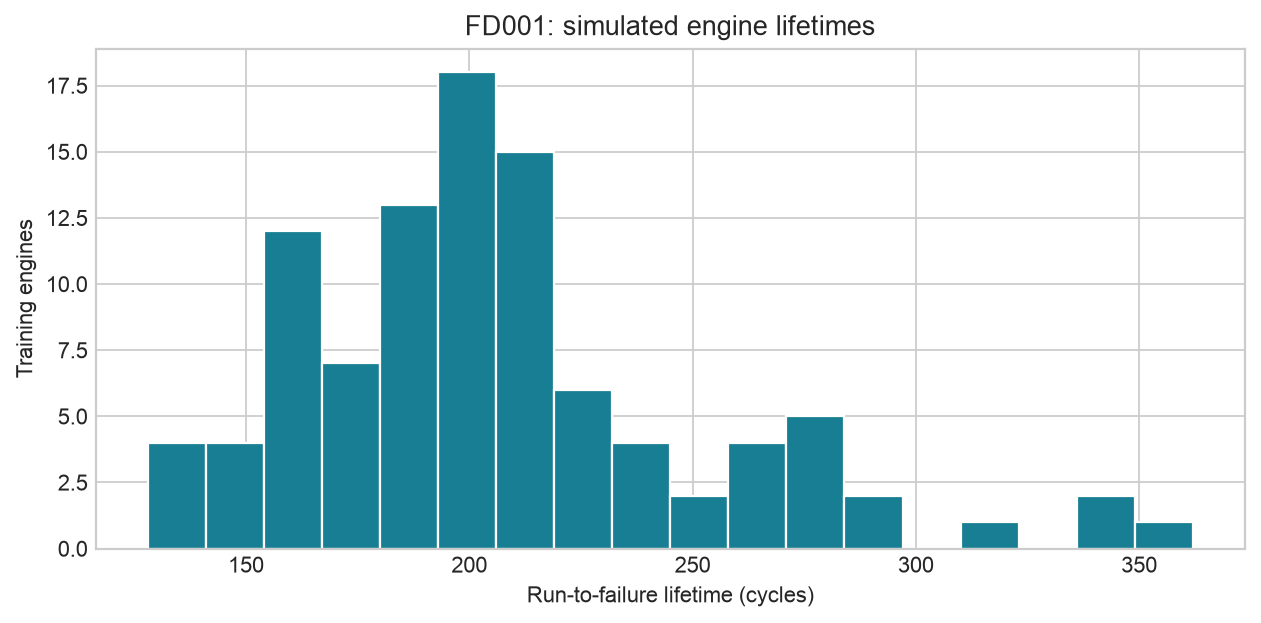

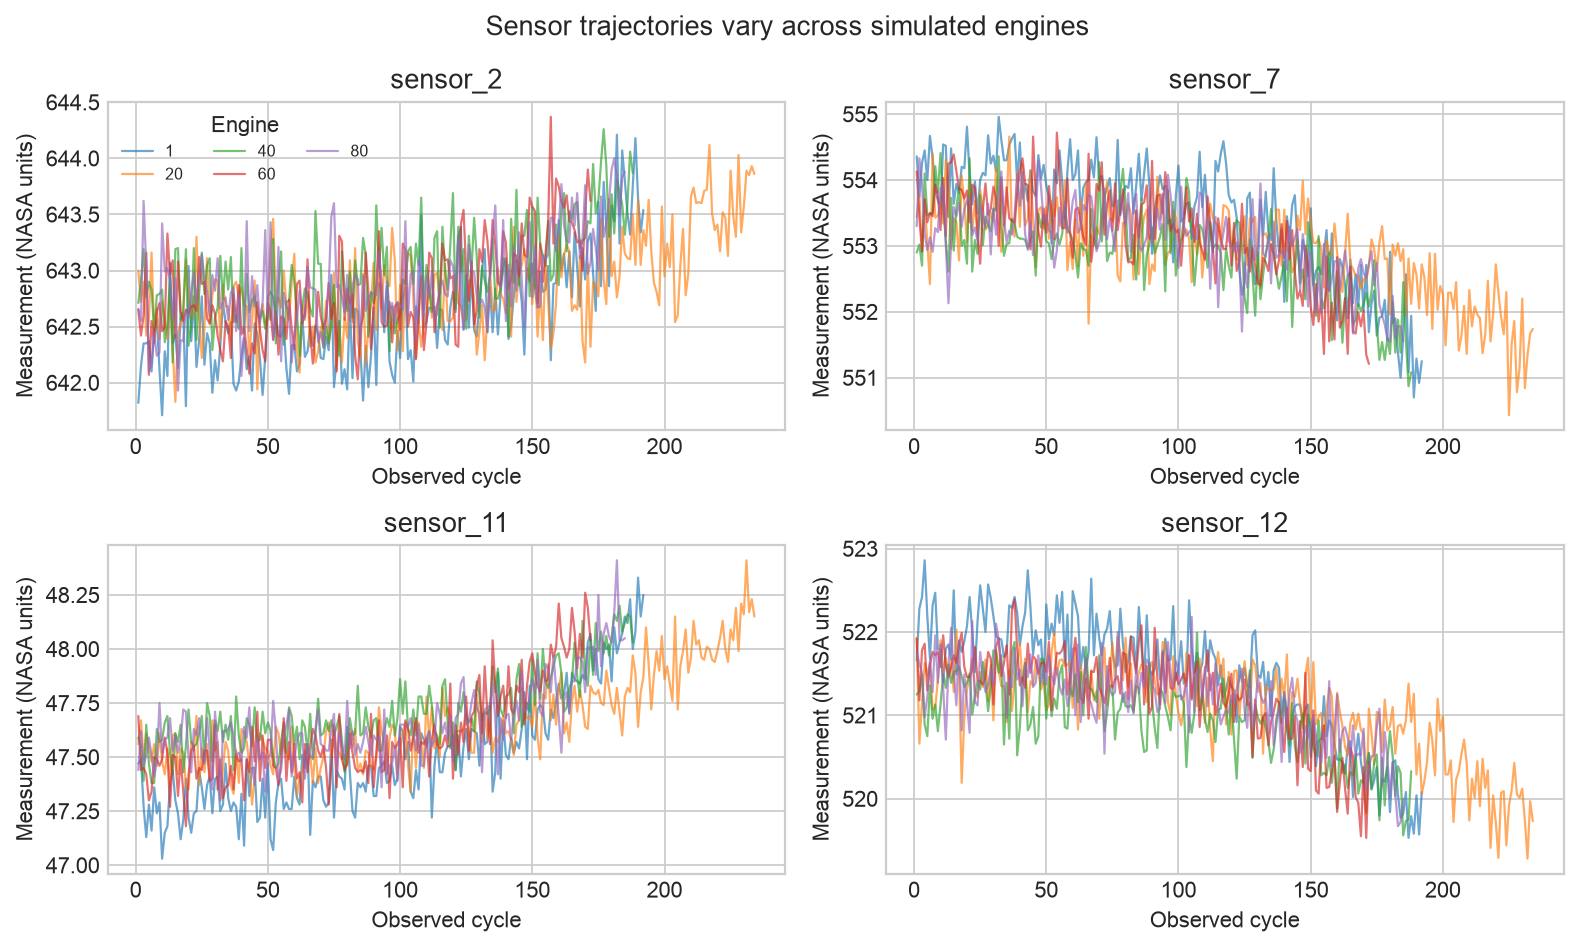

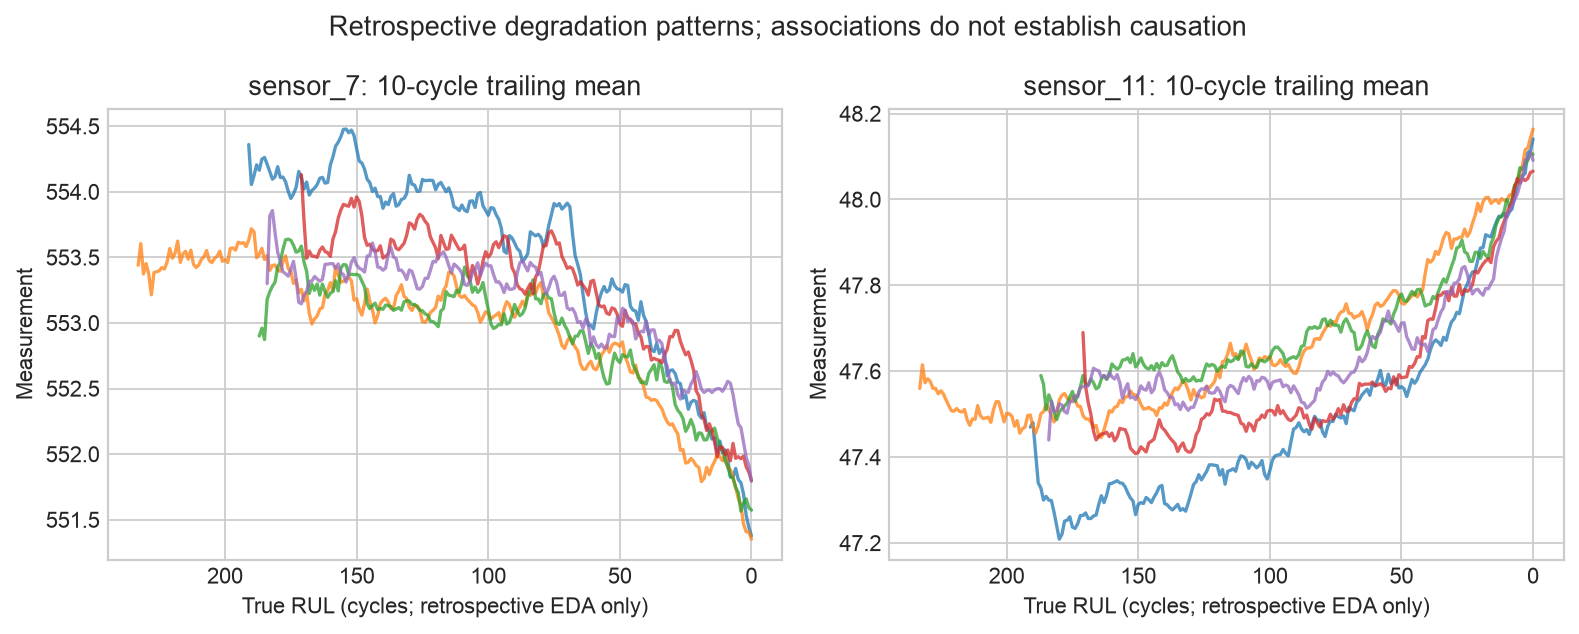

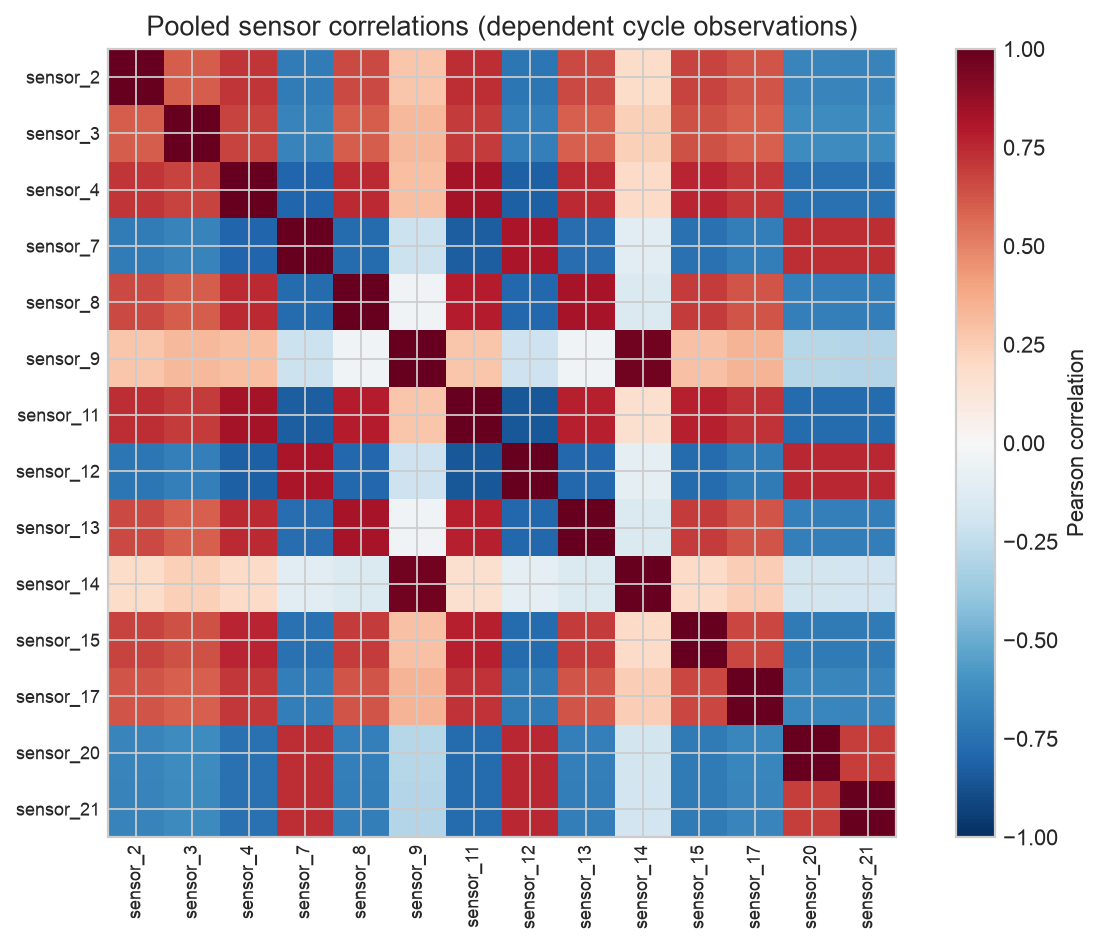

In [3]:
quality = json.loads((ROOT / "results/data_quality.json").read_text())
display(pd.DataFrame({k: {x:v for x,v in q.items() if x in ["rows", "engines", "columns", "missing_values", "duplicate_rows", "constant_sensors"]} for k,q in quality.items()}).T)
display(pd.read_csv(ROOT / "results/sensor_summary.csv"))
for figure in ["engine_lifetimes.png", "sensor_trends.png", "degradation_patterns.png", "sensor_correlations.png"]:
    display(Image(filename=str(ROOT / "figures" / figure)))

Sensor patterns describe association under a shared simulation, not causal evidence. Aligning curves by eventual RUL is retrospective EDA only and is never part of feature generation. Pooled correlations combine within-engine and between-engine variation and do not represent independent cycle samples.

### Model comparison and official test evaluation
Metrics are measured in cycles against **uncapped** labels. Validation chooses the method; only the selected, refitted method is evaluated on the official test set. Test engine i aligns with label line i after verifying IDs 1..100 in ascending order.

,model,mae,rmse,mean_error
0,Histogram gradient boosting,24.986149,31.572042,10.529111
1,Ridge,30.316195,35.372239,20.929180
2,Mean baseline,39.762167,46.682758,27.213720


,mae,rmse,mean_error
Histogram gradient boosting,19.643969,27.080286,11.47651


,rul_range,n,mae,rmse,mean_error
0,0-30,25,9.319520,15.551655,7.655868
1,31-60,14,13.171063,17.532222,8.529217
2,61-100,28,22.295241,31.939512,15.901245
3,>100,33,27.962039,32.296368,11.866983


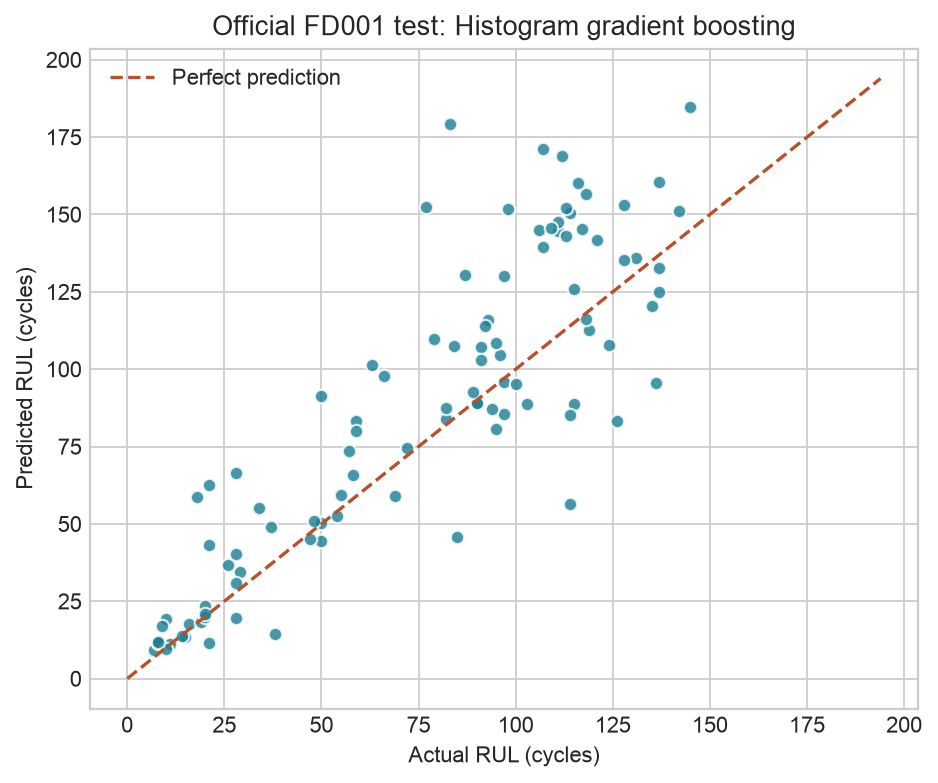

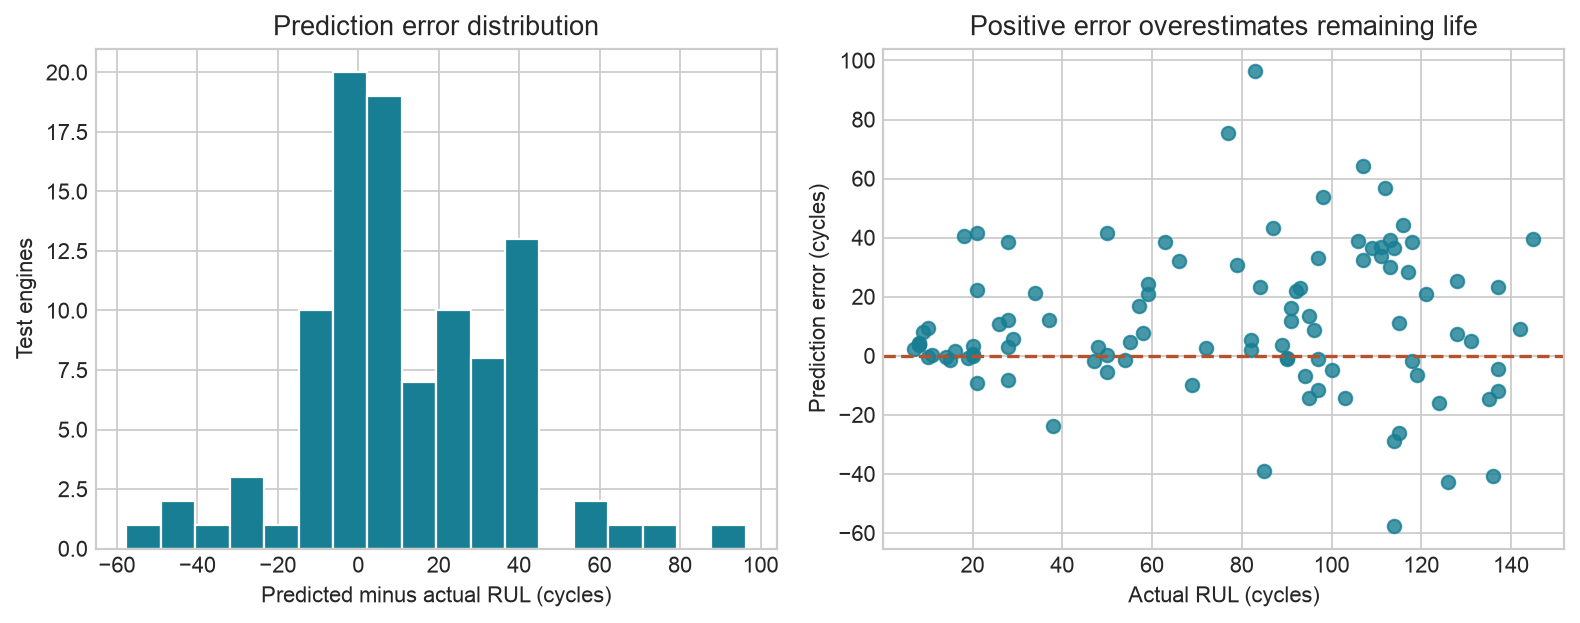

In [4]:
display(pd.read_csv(ROOT / "results/model_comparison.csv"))
display(pd.DataFrame([metrics["test"]], index=[metrics["selected_model"]]))
display(pd.read_csv(ROOT / "results/test_error_by_rul.csv"))
for figure in ["prediction_vs_actual.png", "prediction_errors.png"]:
    display(Image(filename=str(ROOT / "figures" / figure)))

### Interpretation and limitations
Positive prediction error overestimates remaining life, which could delay maintenance if acted on; negative error could imply earlier maintenance and added cost. This analysis does not estimate those costs or define safe maintenance thresholds. MAE/RMSE weight errors symmetrically; RMSE emphasizes large misses.

The mean predictor is transparent but ignores condition. Ridge provides an additive reference but correlated standardized features complicate coefficient interpretation. Boosting captures nonlinear associations with less direct interpretability. Report the actual validation winner without a state-of-the-art claim.

Simulation, one operating condition, one fault mode, 100 training engines, a single engine split, correlated validation snapshots, and censoring mismatch limit external validity. Training uses all cycles, so longer engines contribute more fitting rows. There are no calibrated uncertainty intervals, external fleet data, causal estimates, real-aircraft tests, production deployment, or future-sensor forecasting. Lifetime variability and near-constant sensors motivate careful validation; neither guarantees a real-world benefit.

Reproduce from a fresh environment using the commands in README.md; generated CSV/JSON files retain per-engine predictions and complete method settings.